<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS07/JS07-01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---


# **Klasterisasi - Lab 1**


---

---


# **Langkah 1 - Import Library**


---

In [1]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

---


# **Langkah 2 - Load dan Inspeksi Data**


---

In [2]:
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


> `pd.read_csv()` memuat Iris.csv ke dalam DataFrame `df`, lalu `df.head()` menampilkan 5 baris pertama. Terlihat ada kolom `Id`, empat kolom fitur numerik (panjang dan lebar sepal serta petal, dalam cm), dan kolom `Species` yang berisi label bunga. Label ini sebenarnya tidak dibutuhkan untuk klasterisasi, karena K-Means termasuk unsupervised learning.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


> `df.info()` menunjukkan data terdiri dari 150 baris dan 6 kolom, dengan jumlah *non-null* 150 di semua kolom. Artinya tidak ada *missing values*, sehingga data bisa langsung dipakai tanpa proses pembersihan. Keempat kolom fitur bertipe `float64`, jadi sudah siap dihitung jaraknya oleh K-Means.

---


# **Langkah 3 - Seleksi Fitur**


---

In [4]:
# Features Selection
X = df.iloc[:, 1:-1] # slice the features
y = df.iloc[:, -1] # this is the labels (we don't need it)

In [5]:
print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


> `df.iloc[:, 1:-1]` mengambil kolom ke-1 sampai sebelum kolom terakhir, sehingga kolom `Id` (indeks 0) dan `Species` (kolom terakhir) tidak ikut dipakai. Hasilnya `X` hanya berisi 4 fitur numerik, sedangkan `y` menyimpan label yang tidak akan dipakai untuk melatih model. Pemisahan ini penting supaya model klasterisasi benar-benar belajar dari fitur saja, tanpa bocoran label.

---


# **Langkah 4 - Plotting**


---

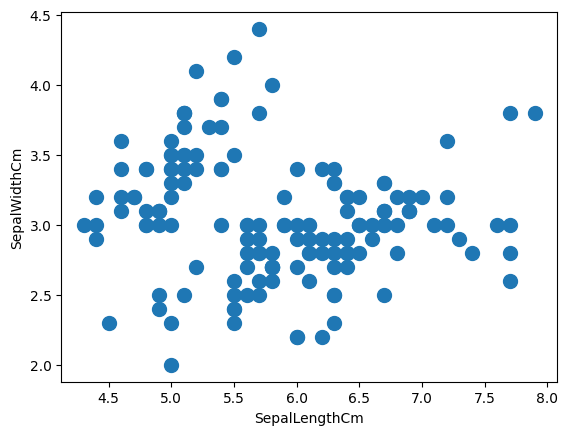

In [6]:
# Make a scatterplot using
# SepalLengthCm and SepalWidthCm
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

> Scatter plot ini menampilkan sebaran data berdasarkan `SepalLengthCm` (sumbu x) dan `SepalWidthCm` (sumbu y). Secara visual titik-titik terlihat membentuk kira-kira dua kelompok, sehingga di langkah berikutnya jumlah klaster diasumsikan 2. Kesimpulan ini baru perkiraan awal dari dua fitur saja, dan nanti diuji lagi dengan Elbow Method.

---


# **Langkah 5 - Membuat Model K-Means**


---

In [7]:
# Build a K-Means Model
# Based on visual inspection using scatterplot,
# we can assumpt that the data has 2 cluster
# (even though, from the label, there are 3 labels in this data)

from sklearn.cluster import KMeans

# Initiate K-Means object with numbur of cluster is 2
cl_kmeans = KMeans(n_clusters=2)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

> `KMeans(n_clusters=2)` membuat model dengan 2 klaster, lalu `fit_predict(X)` melatih model sekaligus menghasilkan label klaster (0 atau 1) untuk setiap data, yang disimpan di `y_kmeans`. Model ini memakai keempat fitur di `X`, bukan hanya dua fitur yang diplot sebelumnya. Titik pusat awal (centroid) dipilih secara acak, jadi hasil antar-run bisa sedikit berbeda.

Setelah model mempelajari data yang kita miliki melalui fungsi fit_predict(), kita dapat melakukan pengecekan hasil klasterisasi dengan memanfaatkan scatterplot.

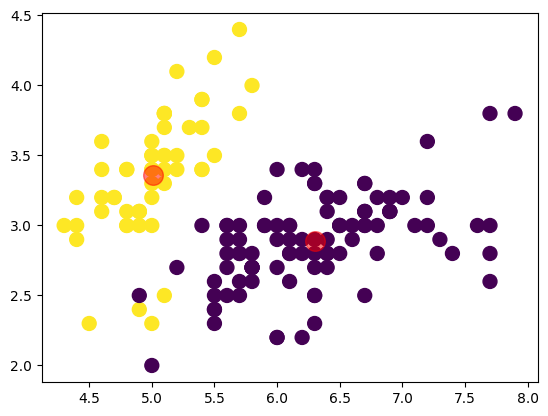

In [8]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

> Titik data diwarnai berdasarkan klaster hasil `y_kmeans`, dan titik merah besar adalah centroid yang diambil dari `cluster_centers_`. Setiap centroid adalah rata-rata posisi semua anggota klasternya, dan setiap titik masuk ke klaster dengan centroid terdekat. Jika dibandingkan dengan label `Species`, k = 2 cenderung memisahkan setosa dari dua spesies lainnya, sedangkan versicolor dan virginica menyatu dalam satu klaster.

---


# **Langkah 6 - Evaluasi Model**


---

In [9]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


> `inertia_` adalah nilai SSE (*sum of squared error*), yaitu jumlah kuadrat jarak setiap titik ke centroid klasternya. Hasil `152.37` untuk k = 2 menunjukkan seberapa rapat anggota klaster mengumpul, dan makin kecil berarti makin rapat. Nilai ini belum bisa dinilai bagus atau jelek sendirian, baru berguna kalau dibandingkan dengan SSE pada k lain. Karena centroid awal acak, angka di run lain bisa sedikit berbeda.

---


# **Langkah 7 - Menentukan k terbaik dengan Elbow Method**


---

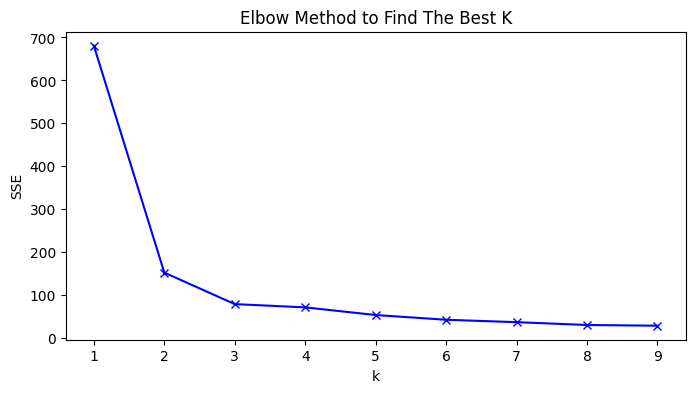

In [10]:
# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1,10)

# Find the SSE value for each k
for k in K:
	kmeanModel = KMeans(n_clusters=k)
	kmeanModel.fit(X)
	sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

> Kode ini melatih K-Means untuk k = 1 sampai 9, menyimpan SSE tiap k ke list `sse`, lalu memplotnya sebagai grafik garis (Elbow Method). SSE pasti turun seiring bertambahnya k, jadi yang dicari bukan SSE terkecil, melainkan titik "siku" tempat penurunan berubah dari curam menjadi landai. Pada grafik, SSE turun tajam dari k = 1 ke k = 3 (sekitar 681, 152, lalu 79), kemudian penurunannya melandai, sehingga k = 3 dipilih sebagai jumlah klaster terbaik. Hasil ini sesuai dengan jumlah spesies asli di dataset, yaitu 3. Karena centroid awal ditentukan secara acak dan tanpa `random_state`, nilai SSE tiap k bisa sedikit berbeda setiap kode dijalankan ulang, tetapi bentuk grafik dan posisi siku tetap sama.